# Session Recurrent Network Viewer

Load a network fitted directly to one recurrent neural dataset, then compare target activity with individual network units and inspect each session's dense recurrent weights.

Each session has one unit per unique neuron in its activity array. New networks infer their initial states from the first observed target time bins; legacy checkpoints retain same initial state inferred from the observed target prefix (zero for legacy checkpoints)s. Every simulation samples fresh input noise, including during evaluation.


In [1]:
%matplotlib inline

import importlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.decomposition import PCA
from utils import experiment_param

import _8_LatentNetwork as ln
importlib.reload(ln)

dirpath = '/Users/kimchm/Documents/KimNiNature2024/MatConverted2Python/' 
par = experiment_param.ExperimentParam(dirpath)

def return_checkpoint_path(n_input_components, recurrent_type, recurrent_rank):

    device = 'cpu'  # 'cuda', 'cuda:0', 'mps', or 'gpu' if available.
    dataset_id = '0'  # filename ID: activity0.npy
    n_input_types = 2
    n_input_components = n_input_components
    input_noise_std = 0.1
    recurrent_type = recurrent_type  # 'fullconn' or 'lowrank'
    recurrent_rank = recurrent_rank  # set a positive integer for lowrank
    checkpoint_path = Path(ln.latent_network_checkpoint_path(
        dataset_id=dataset_id,
        n_input_types=n_input_types,
        n_input_components=n_input_components,
        input_noise_std=input_noise_std,
        recurrent_type=recurrent_type,
        recurrent_rank=recurrent_rank,
    ))
    print('available datasets:', ln.available_training_datasets())
    print('checkpoint:', checkpoint_path)
    print('exists:', checkpoint_path.exists())
    print('device:', device)
    return checkpoint_path


## Load The Trained Model

`results` contains the session networks, the selected dataset, and loss history. Train this checkpoint first if it does not exist:

```python
results = ln.train_latent_network(
    dataset_id=dataset_id,
    n_input_types=n_input_types,
    n_input_components=n_input_components,
    input_noise_std=input_noise_std,
    checkpoint_path=str(checkpoint_path),
    device=device,
    recurrent_type=recurrent_type,
    recurrent_rank=recurrent_rank,
)
```


In [2]:
checkpoint_path_fullconn = return_checkpoint_path(n_input_components=1, recurrent_type='fullconn', recurrent_rank=None)
checkpoint_path_lowrank  = return_checkpoint_path(n_input_components=1, recurrent_type='lowrank', recurrent_rank=10)

results_fc = ln.load_latent_network(checkpoint_path=str(checkpoint_path_fullconn), device='cpu',)
results_lr  = ln.load_latent_network(checkpoint_path=str(checkpoint_path_lowrank), device='cpu',)

rnn_fc  = results_fc['rnn']
loss_fc = results_fc['loss_history']
rnn_lr  = results_lr['rnn']
loss_lr = results_lr['loss_history']
loss_history_by_session_lr = results_lr['loss_history_by_session']

dataset = results_fc['dataset']
n_sessions = rnn_fc.n_sessions

available datasets: ['0']
checkpoint: data/training/recurrent/fullconn/latent_network_Dataset0_In1_fullconn.pt
exists: True
device: cpu
available datasets: ['0']
checkpoint: data/training/recurrent/lowrank/latent_network_Dataset0_In1_Rank10_lowrank.pt
exists: True
device: cpu


In [4]:
# Load one CD dot product per session for the selected dataset.
CDdotproduct = np.load(
    Path(ln.TRAINING_DATA_PATH) / f"training_data/CDdotproduct{dataset['id']}.npy",
    allow_pickle=False,
)
print('CDdotproduct shape:', CDdotproduct.shape)
# Access a session's value with CDdotproduct[fx].


CDdotproduct shape: (33,)


In [5]:
# Run the training-data generator first to save neuron_fraction{dataset_id}.npy.
neuron_fraction = np.load(
    Path(ln.TRAINING_DATA_PATH) / f"training_data/neuron_fraction{dataset['id']}.npy",
    allow_pickle=False,
)
print('neuron_fraction shape:', neuron_fraction.shape)
# Access a session's fraction with neuron_fraction[fx].


neuron_fraction shape: (33,)


Text(0, 0.5, 'mean squared error')

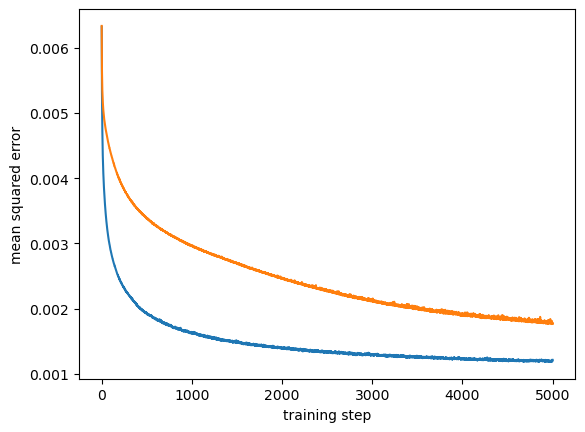

In [6]:
plt.figure()
plt.plot(loss_fc)
plt.plot(loss_lr)
plt.xlabel('training step')
plt.ylabel('mean squared error')


# Data PCA vs. Relearn time

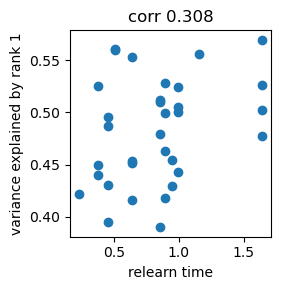

In [7]:
effdim_activity = np.zeros(rnn_lr.n_sessions)
expvar_rank1 = np.zeros(rnn_lr.n_sessions)

cond = 'P1'
for fx in range(rnn_lr.n_sessions):
    activity_fx_cond = results_lr['dataset']['activity'][fx][cond]
    pca = PCA()
    pca.fit(activity_fx_cond.T)
    expvar_activity = np.cumsum(pca.explained_variance_ratio_)
    effdim_activity[fx] = np.where(expvar_activity > 0.9)[0][0] + 1
    expvar_rank1[fx] = expvar_activity[0]
    
relearntime_sorted = par.relearn_time[par.sorted_indices_by_relearn_speed]

plt.figure(figsize=(3,3))    
_cor = np.corrcoef(relearntime_sorted, expvar_rank1)[0,1]
plt.scatter(relearntime_sorted, expvar_rank1)
# plt.scatter(CDdotproduct, expvar_rank1)
plt.title(f'corr {np.round(_cor,decimals=3)}')
plt.xlabel('relearn time')
plt.ylabel('variance explained by rank 1')
# plt.scatter(relearntime_sorted, effdim_activity)
plt.tight_layout()


## Plot Prediction Vs. Target

Rows correspond directly to the same neurons in both target activity and network unit activity. Columns are time bins.


conditions: ('P1', 'A1')
sessions: (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32)
selected session units: 395


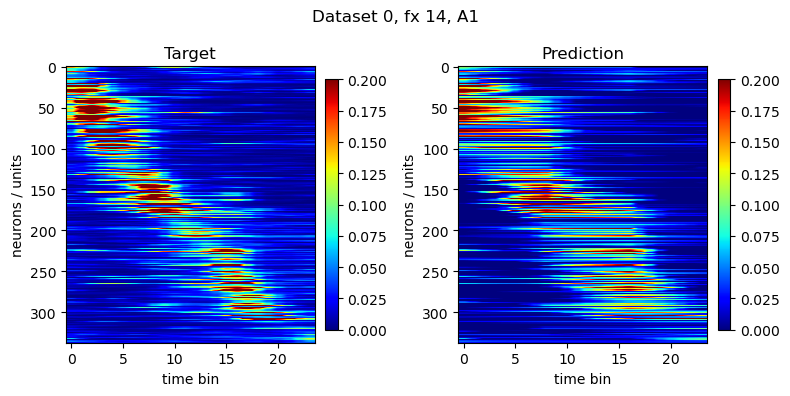

In [8]:
fx = rnn_fc.session_ids[0]
condition = rnn_fc.conditions[0]

print('conditions:', rnn_fc.conditions)
print('sessions:', rnn_fc.session_ids)
print('selected session units:', rnn_fc.n_units_by_session[fx])

ln.plot_prediction_vs_target(
    results_lr,
    fx=14,
    condition='A1',
)
plt.show()


## Inspect The Recurrent Weight Matrix

`W[to_unit, from_unit]` is used in the update through `ReLU(h) @ W.T`. `rnn.recurrent_weight(fx)` returns the selected session's dense, fully trainable matrix. Its shape varies with the session's neuron count.


In [ ]:
wrec_path = Path(ln.SAVE_FIGURE_PATH) / 'wrec'
wrec_path.mkdir(parents=True, exist_ok=True)

for fx_plot in rnn_fc.session_ids:
    W = rnn_fc.recurrent_weight(fx_plot).detach().cpu().numpy()
    plt.figure(figsize=(6, 6))
    wlim = np.max(np.abs(W)) / 4 or 1.0
    plt.imshow(W, cmap='bwr', vmin=-wlim, vmax=wlim, aspect='auto')
    plt.title(f'Recurrent weight W: fx {fx_plot}')
    plt.xlabel('from unit')
    plt.ylabel('to unit')
    plt.colorbar(fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.savefig(wrec_path / f'dataset{dataset["id"]}_w{fx_plot}.png')
    plt.close()


# Wrec explained variance

In [9]:
use_lowrank = True
thr_effdim = 0.8

# Dictionaries accommodate the different neuron counts in each session.
expvar_cumsum = {}
components = {}

for fx_idx in rnn_lr.session_ids:
    if use_lowrank:
        W = rnn_lr.recurrent_weight(fx_idx).detach().cpu().numpy()
    else:
        W = rnn_fc.recurrent_weight(fx_idx).detach().cpu().numpy()
    pca = PCA()
    pca.fit(W.T)
    expvar_cumsum[fx_idx] = np.cumsum(pca.explained_variance_ratio_)
    components[fx_idx] = pca.components_


In [10]:
effdim = np.array([
    int(np.argmax(values > thr_effdim) + 1)
    for fx_idx, values in expvar_cumsum.items()
])
expvar_rank1 = np.array([expvar_cumsum[fx][0] for fx in range(rnn_lr.n_sessions)])

print(effdim)
print(f'sessions with dim <= 4: {np.sum(effdim<=4)}/{len(effdim)}')

[7 8 8 2 6 8 6 8 7 7 4 6 8 7 4 3 7 7 6 2 4 4 6 5 7 8 5 8 6 4 2 2 5]
sessions with dim <= 4: 10/33


Text(0, 0.5, 'explained variance')

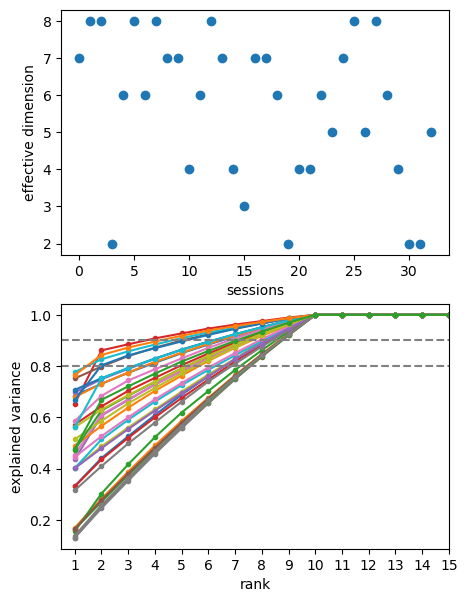

In [11]:
plt.figure(figsize=(5,7))
plt.subplot(211)
plt.plot(effdim,marker='o',linestyle='')
# plt.axhline(3,color='gray',linestyle='--')
plt.xlabel('sessions')
plt.ylabel('effective dimension')
plt.subplot(212)
for fx_idx in rnn_lr.session_ids:
    plt.plot(np.arange(1,len(expvar_cumsum[fx_idx])+1), expvar_cumsum[fx_idx], marker='.')
plt.xlim([0.5, 15])
plt.xticks(np.arange(1,16))
plt.axhline(0.8, color='gray', linestyle='--')
plt.axhline(0.9, color='gray', linestyle='--')
plt.xlabel('rank')
plt.ylabel('explained variance')


# Alignment of CD1 and Wrec principal component

In [12]:
rnn_lr = results_lr['rnn']
dataset = results_lr['dataset']

right_sv = {}
for fx in range(rnn_lr.n_sessions):
    W = rnn_lr.recurrent_weight(fx).detach().cpu().numpy()
    U, S, Vh = np.linalg.svd(W, full_matrices=False)
    V = Vh.T
    right_sv[fx] = V[:,0]


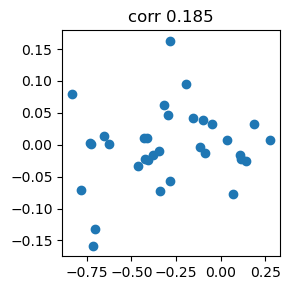

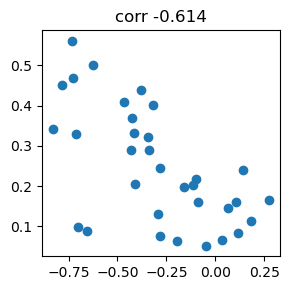

In [13]:


CD1_vs_Wpc = np.zeros(rnn_lr.n_sessions)
CD1_vs_lsv = np.zeros(rnn_lr.n_sessions)
rnn_lr.eval()
for fx in range(rnn_lr.n_sessions):
    with torch.no_grad():
        # Draw fresh noise once per comparison and reuse it for both predictions.
        comparison_input_timecourses = rnn_lr.session_model(fx).sample_input_timecourses()
        comparison_initial_activity = rnn_lr.initial_activity_from_targets(
            fx, dataset["activity"][fx],
        )
        prediction_P1 = rnn_lr(
            fx, input_timecourses=comparison_input_timecourses,
            initial_activity=comparison_initial_activity,
        )['P1'].T.cpu().numpy()

        prediction_A1 = rnn_lr(
            fx, input_timecourses=comparison_input_timecourses,
            initial_activity=comparison_initial_activity,
        )['A1'].T.cpu().numpy()
        

    P1rate = np.mean(prediction_P1[:,12:16],axis=1)
    A1rate = np.mean(prediction_A1[:,12:16],axis=1)
    CD1 = P1rate - A1rate
    
    CD1_vs_lsv[fx] = np.inner(right_sv[fx],CD1) / np.linalg.norm(right_sv[fx]) / np.linalg.norm(CD1)
    
    Wpc = components[fx][:,0]
    CD1_vs_Wpc[fx] = np.inner(CD1, Wpc) / np.linalg.norm(CD1) / np.linalg.norm(Wpc)

plt.figure(figsize=(3,3))
_cor = np.corrcoef(CDdotproduct, CD1_vs_Wpc)[0,1]
plt.scatter(CDdotproduct, CD1_vs_Wpc)
plt.title(f'corr {np.round(_cor,decimals=3)}')
plt.tight_layout()

plt.figure(figsize=(3,3))
_cor = np.corrcoef(CDdotproduct, np.abs(CD1_vs_lsv))[0,1]
plt.scatter(CDdotproduct, np.abs(CD1_vs_lsv))
plt.title(f'corr {np.round(_cor,decimals=3)}')
plt.tight_layout()



# Session loss vs. CD dot product

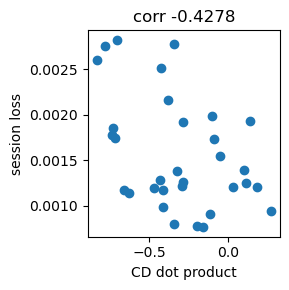

In [14]:
session_loss_lr = np.zeros(rnn_lr.n_sessions)
for fx in range(33):
    _loss_fx = np.asarray(loss_history_by_session_lr[fx], dtype=float)
    session_loss_lr[fx] = _loss_fx[-1]

idx = session_loss_lr < 0.004
plt.figure(figsize=(3,3))
_cor = np.corrcoef(CDdotproduct[idx],session_loss_lr[idx])[0,1]
plt.scatter(CDdotproduct[idx],session_loss_lr[idx])
plt.title(f'corr {np.round(_cor,decimals=4)}')
plt.xlabel('CD dot product')
plt.ylabel('session loss')
plt.tight_layout()



# Relearn time vs. Dimension of Wrec

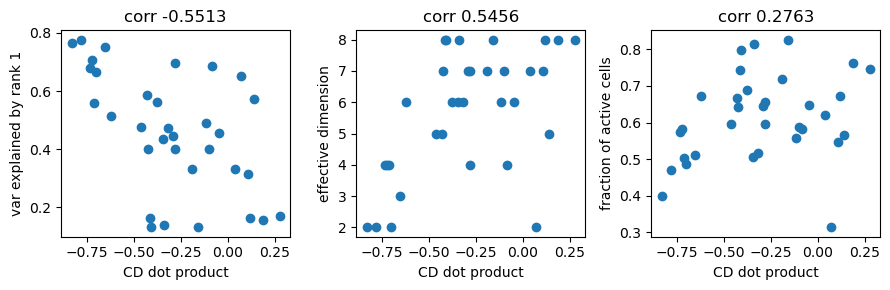

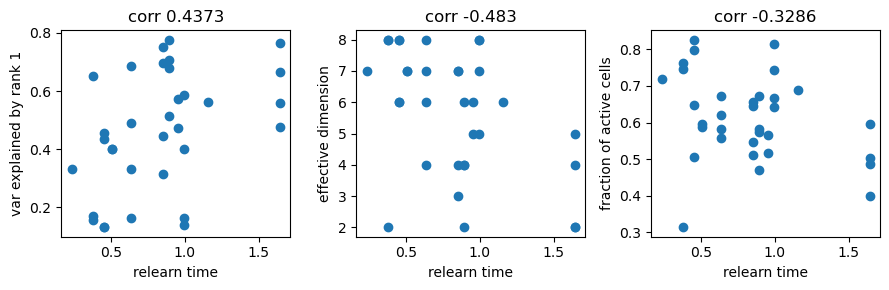

In [15]:
plt.figure(figsize=(9,3))
plt.subplot(131)
_cor = np.corrcoef(CDdotproduct,expvar_rank1)[0,1]
plt.scatter(CDdotproduct,expvar_rank1)
plt.title(f'corr {np.round(_cor,decimals=4)}')
plt.xlabel('CD dot product')
plt.ylabel('var explained by rank 1')
plt.subplot(132)
_cor = np.corrcoef(CDdotproduct,effdim)[0,1]
plt.scatter(CDdotproduct,effdim)
plt.title(f'corr {np.round(_cor,decimals=4)}')
plt.xlabel('CD dot product')
plt.ylabel('effective dimension')
plt.subplot(133)
_cor = np.corrcoef(CDdotproduct,neuron_fraction)[0,1]
plt.scatter(CDdotproduct,neuron_fraction)
plt.title(f'corr {np.round(_cor,decimals=4)}')
plt.xlabel('CD dot product')
plt.ylabel('fraction of active cells')
plt.tight_layout()


relearntime_sorted = par.relearn_time[par.sorted_indices_by_relearn_speed]
plt.figure(figsize=(9,3))
plt.subplot(131)
_cor = np.corrcoef(relearntime_sorted,expvar_rank1)[0,1]
plt.scatter(relearntime_sorted,expvar_rank1)
plt.title(f'corr {np.round(_cor,decimals=4)}')
plt.xlabel('relearn time')
plt.ylabel('var explained by rank 1')
plt.subplot(132)
_cor = np.corrcoef(relearntime_sorted,effdim)[0,1]
plt.scatter(relearntime_sorted,effdim)
plt.title(f'corr {np.round(_cor,decimals=4)}')
plt.xlabel('relearn time')
plt.ylabel('effective dimension')
plt.subplot(133)
_cor = np.corrcoef(relearntime_sorted,neuron_fraction)[0,1]
plt.scatter(relearntime_sorted,neuron_fraction)
plt.title(f'corr {np.round(_cor,decimals=4)}')
plt.xlabel('relearn time')
plt.ylabel('fraction of active cells')
plt.tight_layout()




# Active cells vs. Dimension of Wrec

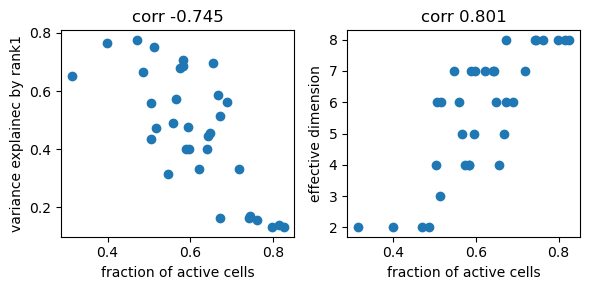

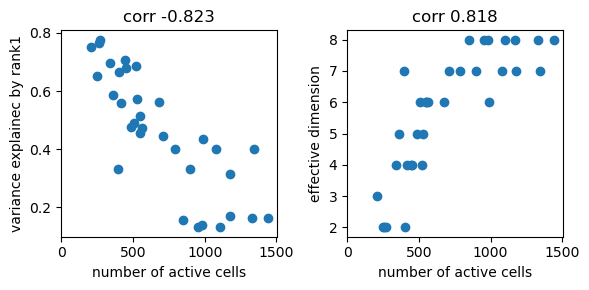

In [16]:
ncells = np.zeros(rnn_lr.n_sessions)
condition = 'P1'
for fx in range(rnn_lr.n_sessions):
    target = np.asarray(dataset['activity'][fx][condition])
    ncells[fx] = target.shape[0]

plt.figure(figsize=(6,3))
plt.subplot(121)
_cor = np.corrcoef(neuron_fraction,expvar_rank1)[0,1]
plt.scatter(neuron_fraction,expvar_rank1)
plt.title(f'corr {np.round(_cor,decimals=3)}')
plt.xlabel('fraction of active cells')
plt.ylabel('variance explainec by rank1')

plt.subplot(122)
_cor = np.corrcoef(neuron_fraction,effdim)[0,1]
plt.scatter(neuron_fraction,effdim)
plt.title(f'corr {np.round(_cor,decimals=3)}')
plt.xlabel('fraction of active cells')
plt.ylabel('effective dimension')
plt.tight_layout()


plt.figure(figsize=(6,3))
plt.subplot(121)
_cor = np.corrcoef(ncells,expvar_rank1)[0,1]
plt.scatter(ncells,expvar_rank1)
plt.title(f'corr {np.round(_cor,decimals=3)}')
plt.xlabel('number of active cells')
plt.ylabel('variance explainec by rank1')
plt.xticks([0,500,1000,1500])

plt.subplot(122)
_cor = np.corrcoef(ncells,effdim)[0,1]
plt.scatter(ncells,effdim)
plt.title(f'corr {np.round(_cor,decimals=3)}')
plt.xlabel('number of active cells')
plt.ylabel('effective dimension')
plt.xticks([0,500,1000,1500])
plt.tight_layout()



# Relearn time vs. Recurrent weight norm

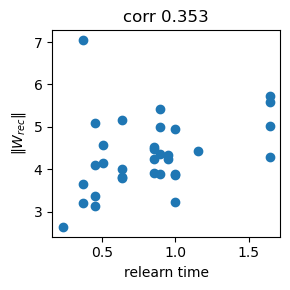

In [17]:
# L2 norm of all entries in W (Frobenius norm), stored by network and session.
# For low-rank networks, recurrent_weight() reconstructs the scaled U @ V.T.
latent_networks = {'fullconn': rnn_fc, 'lowrank': rnn_lr}
recurrent_weight_l2 = {}

with torch.no_grad():
    for network_name, network in latent_networks.items():
        recurrent_weight_l2[network_name] = np.zeros(network.n_sessions)
        for fx_norm in network.session_ids:
            W_norm = network.recurrent_weight(fx_norm)
            recurrent_weight_l2[network_name][fx_norm] = torch.linalg.vector_norm(
                W_norm.reshape(-1), ord=2,
            ).item()

# Access a session with recurrent_weight_l2['fullconn'][fx] or ['lowrank'][fx].
wrec_l2_lowrank = recurrent_weight_l2['lowrank']
wrec_l2_fullconn = recurrent_weight_l2['fullconn']

plt.figure(figsize=(3,3))
if use_lowrank:
    _cor = np.corrcoef(relearntime_sorted, wrec_l2_lowrank)[0,1]
    plt.scatter(relearntime_sorted, wrec_l2_lowrank)
else:
    _cor = np.corrcoef(relearntime_sorted, wrec_l2_fullconn)[0,1]
    plt.scatter(relearntime_sorted, wrec_l2_fullconn)
plt.xlabel('relearn time')
plt.ylabel(r'$\Vert W_{rec}\Vert$')
plt.title(f'corr {np.round(_cor,decimals=3)}')
plt.tight_layout()


In [380]:
# Compare the first 200 neurons, with at most 100 neurons per figure.
use_lowrank = False
if use_lowrank:
    compare_results = results_lr  # Use results_fc to inspect the fully connected model.
else:
    compare_results = results_fc
rnn_rl = results_lr['rnn']
dataset = results_lr['dataset']
fx = 4
condition = 'A1'
# truncation_rank = effdim[compare_fx]  # Number of leading singular components retained during simulation.

# target = np.asarray(dataset['activity'][compare_fx][compare_condition])
# was_training = rnn_rl.training
num_zero_activity = np.zeros(rnn_rl.n_sessions)
frac_zero_activity = np.zeros(rnn_rl.n_sessions)
rnn_rl.eval()
for fx in range(rnn_rl.n_sessions):
    with torch.no_grad():
        # Draw fresh noise once per comparison and reuse it for both predictions.
        comparison_input_timecourses = rnn_rl.session_model(fx).sample_input_timecourses()
        comparison_initial_activity = rnn_rl.initial_activity_from_targets(
            fx, dataset["activity"][fx],
        )
        prediction = rnn_rl(
            fx, input_timecourses=comparison_input_timecourses,
            initial_activity=comparison_initial_activity,
        )[condition].T.cpu().numpy()
    sum_of_activity = np.sum(prediction,axis=1)
    frac_zero_activity[fx] = np.sum(sum_of_activity==0) / len(sum_of_activity)
    num_zero_activity[fx] = np.sum(sum_of_activity==0) 

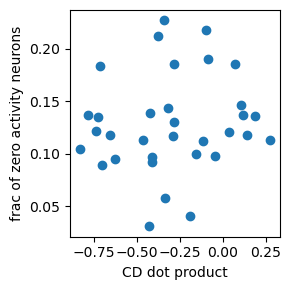

In [387]:
plt.figure(figsize=(3,3))
plt.scatter(CDdotproduct, frac_zero_activity)
plt.xlabel('CD dot product')
plt.ylabel('frac of zero activity neurons')
plt.tight_layout()


# Target vs. Prediction (Wrec and Truncated Wrec)

Session 4, Effective dim 5, Truncation Rank 2


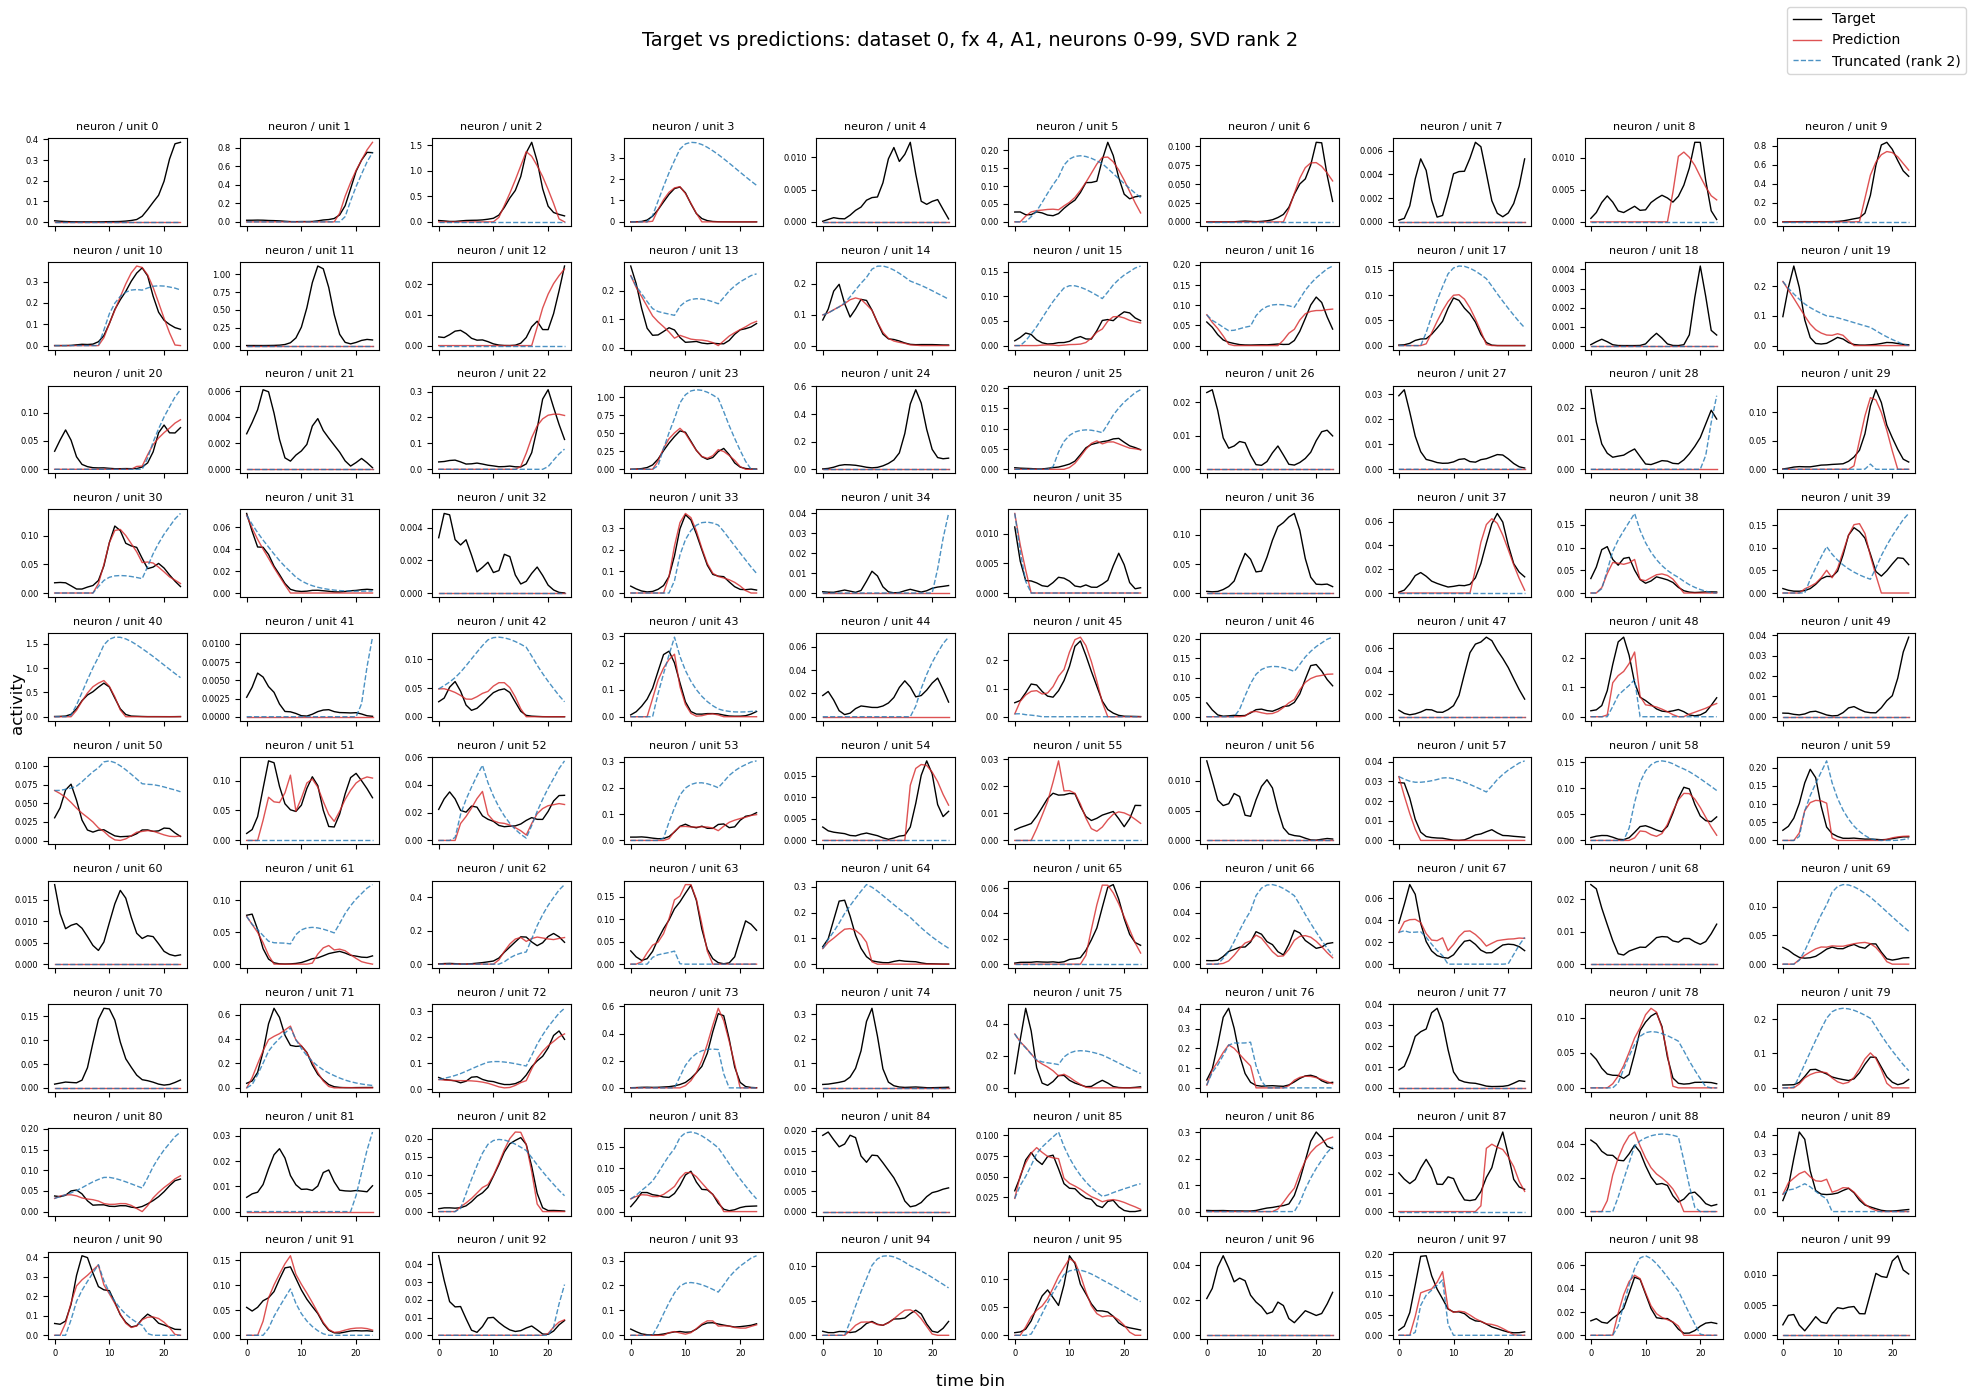

In [376]:
# Compare the first 200 neurons, with at most 100 neurons per figure.
use_lowrank = False
if use_lowrank:
    compare_results = results_lr  # Use results_fc to inspect the fully connected model.
else:
    compare_results = results_fc
compare_rnn = compare_results['rnn']
compare_dataset = compare_results['dataset']
compare_fx = 4
compare_condition = 'A1'
# truncation_rank = effdim[compare_fx]  # Number of leading singular components retained during simulation.
truncation_rank = 2  # Number of leading singular components retained during simulation.
max_neurons_to_plot = 100
neurons_per_figure = 100

print(f'Session {compare_fx}, Effective dim {effdim[compare_fx]}, Truncation Rank {truncation_rank}')

target = np.asarray(compare_dataset['activity'][compare_fx][compare_condition])
was_training = compare_rnn.training
compare_rnn.eval()
try:
    with torch.no_grad():
        # Draw fresh noise once per comparison and reuse it for both predictions.
        comparison_input_timecourses = compare_rnn.session_model(compare_fx).sample_input_timecourses()
        comparison_initial_activity = compare_rnn.initial_activity_from_targets(
            compare_fx, compare_dataset["activity"][compare_fx],
        )
        prediction = compare_rnn(
            compare_fx, input_timecourses=comparison_input_timecourses,
            initial_activity=comparison_initial_activity,
        )[compare_condition].T.cpu().numpy()
        prediction_truncated = compare_rnn(
            compare_fx, truncation_rank=truncation_rank,
            input_timecourses=comparison_input_timecourses,
            initial_activity=comparison_initial_activity,
        )[compare_condition].T.cpu().numpy()
finally:
    compare_rnn.train(was_training)

assert target.shape == prediction.shape == prediction_truncated.shape
n_neurons = min(target.shape[0], max_neurons_to_plot)
time_bins = np.arange(target.shape[1])

for start in range(0, n_neurons, neurons_per_figure):
    stop = min(start + neurons_per_figure, n_neurons)
    fig, axes = plt.subplots(10, 10, figsize=(20, 14), sharex=True)
    axes = axes.ravel()
    for ax_idx, ax in enumerate(axes):
        neuron_idx = start + ax_idx
        if neuron_idx >= stop:
            ax.set_visible(False)
            continue
        ax.plot(time_bins, target[neuron_idx], color='black', lw=1, label='Target')
        ax.plot(time_bins, prediction[neuron_idx], color='tab:red', lw=1,
                alpha=0.8, label='Prediction')
        ax.plot(time_bins, prediction_truncated[neuron_idx], color='tab:blue', lw=1,
                linestyle='--', alpha=0.8, label=f'Truncated (rank {truncation_rank})')
        ax.set_title(f'neuron / unit {neuron_idx}', fontsize=8)
        ax.tick_params(labelsize=6, labelbottom=neuron_idx + 10 >= stop)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper right')
    fig.suptitle(
        f'Target vs predictions: dataset {compare_dataset["id"]}, fx {compare_fx}, '
        f'{compare_condition}, neurons {start}-{stop - 1}, SVD rank {truncation_rank}', fontsize=14,
    )
    fig.supxlabel('time bin')
    fig.supylabel('activity')
    fig.tight_layout(rect=[0, 0, 0.98, 0.95])
    plt.show()


In [337]:
# Compare the first 200 neurons, with at most 100 neurons per figure.
compare_results = results_lr  # Use results_fc to inspect the fully connected model.
compare_rnn = compare_results['rnn']
compare_dataset = compare_results['dataset']
compare_rnn.eval()

r2_pred_targ = {}
r2_pred_trun = {}

maxrank = 9
compare_condition = 'A1'
for compare_fx in range(compare_rnn.n_sessions):
    target = np.asarray(compare_dataset['activity'][compare_fx][compare_condition])
    with torch.no_grad():
        comparison_input_timecourses = compare_rnn.session_model(compare_fx).sample_input_timecourses()
        comparison_initial_activity = compare_rnn.initial_activity_from_targets(
            compare_fx, compare_dataset["activity"][compare_fx],
        )
        prediction = compare_rnn(
            compare_fx, input_timecourses=comparison_input_timecourses,
            initial_activity=comparison_initial_activity,
        )[compare_condition].T.cpu().numpy()
    nonzeros = np.sum(prediction,axis=1) > 0
    mse_pred_targ = np.mean((target - prediction)**2,axis=1)[nonzeros]
    var_targ = np.var(target,axis=1)[nonzeros]
    _r2_pred_targ = 1 - mse_pred_targ/var_targ 
    r2_pred_targ[compare_fx] = _r2_pred_targ


for truncation_rank in np.arange(1,maxrank+1):
    rankx_r2_pred_trun = {}   
    for compare_fx in range(compare_rnn.n_sessions):
        with torch.no_grad():
            # Draw fresh noise once per comparison and reuse it for both predictions.
            comparison_input_timecourses = compare_rnn.session_model(compare_fx).sample_input_timecourses()
            comparison_initial_activity = compare_rnn.initial_activity_from_targets(
                compare_fx, compare_dataset["activity"][compare_fx],
            )
            prediction = compare_rnn(
                compare_fx, input_timecourses=comparison_input_timecourses,
                initial_activity=comparison_initial_activity,
            )[compare_condition].T.cpu().numpy()
            prediction_truncated = compare_rnn(
                compare_fx, truncation_rank=truncation_rank,
                input_timecourses=comparison_input_timecourses,
                initial_activity=comparison_initial_activity,
            )[compare_condition].T.cpu().numpy()

        nonzeros = np.sum(prediction,axis=1) > 0
        mse_pred_trun = np.mean((prediction_truncated - prediction)**2,axis=1)[nonzeros]
        var_pred = np.var(prediction,axis=1)[nonzeros]
        _r2_pred_trun = 1 - mse_pred_trun/var_pred 
        rankx_r2_pred_trun[compare_fx] = _r2_pred_trun
    r2_pred_trun[truncation_rank] = rankx_r2_pred_trun
    


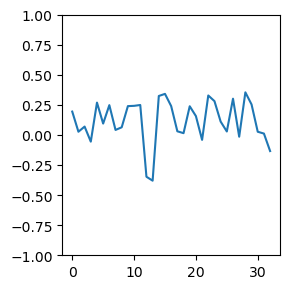

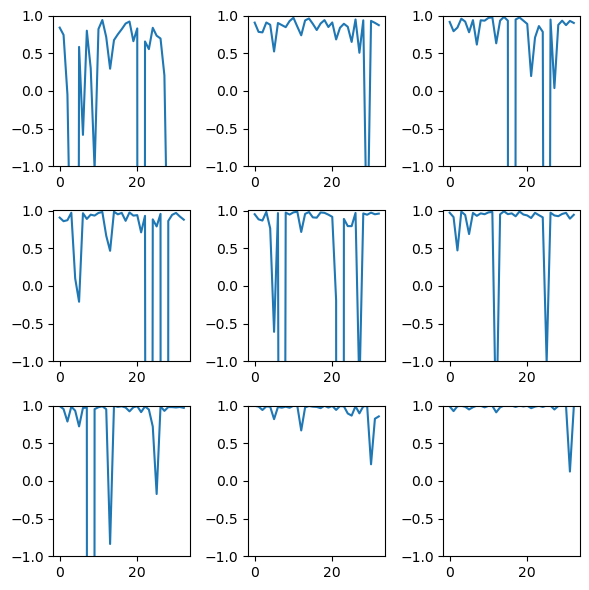

In [338]:
mean_r2_pred_targ = np.zeros(compare_rnn.n_sessions)
mean_r2_pred_trun = np.zeros((maxrank,compare_rnn.n_sessions))
for fx in range(compare_rnn.n_sessions):
    mean_r2_pred_targ[fx] = np.mean(r2_pred_targ[fx])
for rk in np.arange(1,maxrank+1):
    for fx in range(compare_rnn.n_sessions):
        mean_r2_pred_trun[rk-1,fx] = np.mean(r2_pred_trun[rk][fx])

plt.figure(figsize=(3,3))
plt.plot(mean_r2_pred_targ)
plt.ylim([-1,1])
plt.tight_layout()

plt.figure(figsize=(6,6))
for rk in np.arange(maxrank):
    plt.subplot(3,3,rk+1)
    plt.plot(mean_r2_pred_trun[rk])
    plt.ylim([-1,1])
plt.tight_layout()

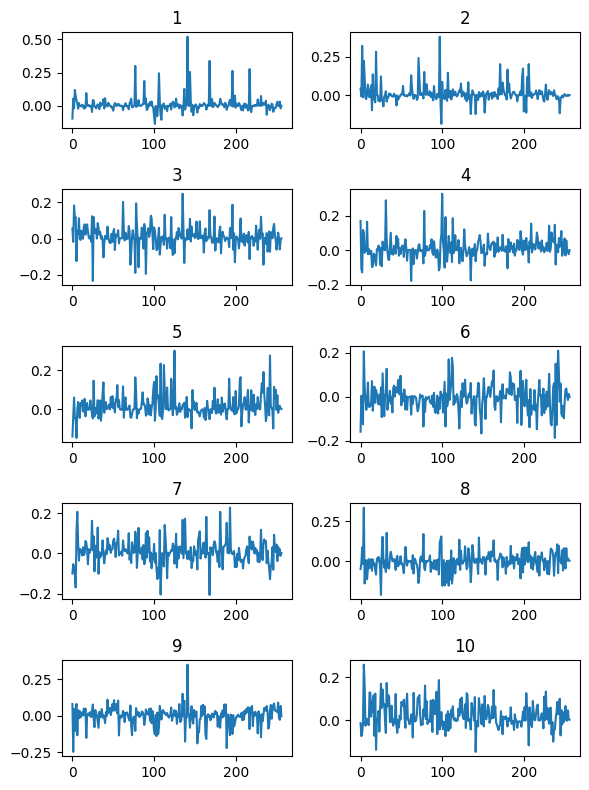

In [321]:
fx1 = rnn.session_ids[min(3, n_sessions - 1)]
fx2 = rnn.session_ids[min(23, n_sessions - 1)]
plt.figure(figsize=(6, 8))
for ic in range(min(10, components[fx2].shape[0])):
    plt.subplot(5, 2, ic + 1)
    plt.plot(components[fx2][ic])
    plt.title(f'{ic + 1}')
plt.tight_layout()


# SVD of the recurrent weights

In [ ]:
fx_svd = rnn.session_ids[min(2, n_sessions - 1)]
W = rnn.recurrent_weight(fx_svd).detach().cpu().numpy()
U, S, Vh = np.linalg.svd(W, full_matrices=False)
cumulative_explained_variance = np.cumsum(S ** 2) / np.sum(S ** 2)

plt.figure(figsize=(4, 3))
plt.plot(cumulative_explained_variance, '.-')
plt.xlabel('number of singular modes')
plt.ylabel('cumulative explained variance')
plt.ylim([0.5, 1.05])
plt.xlim([-1, 5])
plt.tight_layout()
